# PRÁCTICA 2: Predicción de Demanda en Retail
## Deep Learning y Series Temporales

**Asignatura:** Aprendizaje Automático  
**Dataset:** Sintético basado en FreshRetailNet-50K  
**Objetivo:** Desarrollar un modelo de red neuronal recurrente (LSTM/RNN) para predicción de demanda de productos

### Fases del Proyecto
1. **Fase 1:** Análisis y preparación del dataset (EDA, Feature Engineering, Secuencias)
2. **Fase 2:** Desarrollo y entrenamiento de modelos (LSTM/RNN, evaluación RMSE, finetuning)
3. **Fase 3:** Funciones de predicción para producción (single y batch)

## 0. Importación de Librerías y Configuración

In [1]:
# Desactivar GPU ANTES de importar TensorFlow
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import pickle
import json

# Machine Learning
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, RepeatVector, TimeDistributed
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Configurar visualizaciones
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print(f"✓ TensorFlow version: {tf.__version__}")
print(f"✓ Pandas version: {pd.__version__}")
print(f"✓ NumPy version: {np.__version__}")
print(f"✓ GPU Disponible: {len(tf.config.list_physical_devices('GPU'))} GPUs (desactivada)")

I0000 00:00:1792261072.258496  866312 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792261072.258772  866312 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792261073.227741  866312 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792261073.227892  866312 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


✓ TensorFlow version: 2.21.0
✓ Pandas version: 3.0.3
✓ NumPy version: 1.26.4
✓ GPU Disponible: 0 GPUs (desactivada)


## FASE 1: Análisis y Preparación del Dataset
### 1. Cargar datos generados (inventory.csv y sales_history.csv)

In [2]:
# Rutas de datos
base_path = '.'  # carpeta de la práctica
inventory_path = os.path.join(base_path, 'data/inventory.csv')
sales_path = os.path.join(base_path, 'data/sales_history.csv')

# Cargar datos
print("Cargando datos...")
inventory_df = pd.read_csv(inventory_path)
sales_df = pd.read_csv(sales_path)

print(f"✓ Inventory: {inventory_df.shape}")
print(f"✓ Sales History: {sales_df.shape}")
print(f"\nInventory columns: {inventory_df.columns.tolist()}")
print(f"Sales columns: {sales_df.columns.tolist()}")

Cargando datos...
✓ Inventory: (10, 6)
✓ Sales History: (1800, 5)

Inventory columns: ['product_id', 'nombre', 'categoria', 'unidad', 'stock_actual', 'fecha_expiracion']
Sales columns: ['product_id', 'nombre', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento']


### 2. Exploración Inicial y Validación de Estructura

In [3]:
# Exploración de inventory
print("="*70)
print("EXPLORACIÓN DE INVENTORY")
print("="*70)
print(f"\nPrimeras filas:")
print(inventory_df.head())
print(f"\nTipos de datos:")
print(inventory_df.dtypes)
print(f"\nValores faltantes:")
print(inventory_df.isnull().sum())
print(f"\nEstadísticas descriptivas:")
print(inventory_df.describe())

EXPLORACIÓN DE INVENTORY

Primeras filas:
   product_id            nombre    categoria    unidad  stock_actual  \
0           1      Laptop Gamer  Electronica  Unidades           282   
1           2        Monitor 4K  Electronica  Unidades           272   
2           3  Teclado Mecanico   Accesorios  Unidades           194   
3           4       Raton Inal.   Accesorios  Unidades           286   
4           5       Cable USB-C       Cables  Unidades           251   

  fecha_expiracion  
0       2027-10-01  
1       2027-10-01  
2       2027-10-01  
3       2027-10-01  
4       2027-10-01  

Tipos de datos:
product_id          int64
nombre                str
categoria             str
unidad                str
stock_actual        int64
fecha_expiracion      str
dtype: object

Valores faltantes:
product_id          0
nombre              0
categoria           0
unidad              0
stock_actual        0
fecha_expiracion    0
dtype: int64

Estadísticas descriptivas:
       product_id  

In [4]:
# Exploración de sales_history
print("="*70)
print("EXPLORACIÓN DE SALES HISTORY")
print("="*70)
print(f"\nPrimeras filas:")
print(sales_df.head())
print(f"\nÚltimas filas:")
print(sales_df.tail())
print(f"\nTipos de datos:")
print(sales_df.dtypes)
print(f"\nValores faltantes:")
print(sales_df.isnull().sum())
print(f"\nEstadísticas descriptivas:")
print(sales_df.describe())

# Rango de fechas
sales_df['fecha_venta'] = pd.to_datetime(sales_df['fecha_venta'])
print(f"\nRango de fechas: {sales_df['fecha_venta'].min()} a {sales_df['fecha_venta'].max()}")
print(f"Total de días: {(sales_df['fecha_venta'].max() - sales_df['fecha_venta'].min()).days + 1} días")

EXPLORACIÓN DE SALES HISTORY

Primeras filas:
   product_id            nombre fecha_venta  cantidad_vendida  \
0           1      Laptop Gamer  2026-04-05                 2   
1           2        Monitor 4K  2026-04-05                 3   
2           3  Teclado Mecanico  2026-04-05                 5   
3           4       Raton Inal.  2026-04-05                 6   
4           5       Cable USB-C  2026-04-05                 7   

   stock_en_momento  
0               316  
1               299  
2               303  
3               351  
4               330  

Últimas filas:
      product_id           nombre fecha_venta  cantidad_vendida  \
1795           6   Adaptador HDMI  2026-10-01                21   
1796           7        Webcam HD  2026-10-01                10   
1797           8   Auriculares BT  2026-10-01                13   
1798           9      Hub USB 3.0  2026-10-01                 9   
1799          10  Cargador Rapido  2026-10-01                15   

      stock_

In [5]:
# Análisis por producto
print("="*70)
print("ANÁLISIS POR PRODUCTO")
print("="*70)

product_stats = sales_df.groupby('product_id').agg({
    'cantidad_vendida': ['count', 'sum', 'mean', 'std', 'min', 'max'],
    'stock_en_momento': ['mean', 'min', 'max']
}).round(2)

print("\nEstadísticas por producto:")
print(product_stats)

# Resumen por categoría
print("\n" + "="*70)
print("RESUMEN POR CATEGORÍA")
print("="*70)
category_summary = inventory_df.groupby('categoria').agg({
    'product_id': 'count',
    'stock_actual': ['mean', 'sum']
}).round(2)
print(category_summary)

ANÁLISIS POR PRODUCTO

Estadísticas por producto:
           cantidad_vendida                            stock_en_momento      \
                      count   sum   mean   std min max             mean min   
product_id                                                                    
1                       180  1441   8.01  3.17   1  20           140.61  20   
2                       180  2117  11.76  3.99   3  24           124.44   7   
3                       180  2822  15.68  4.67   5  35           118.26   8   
4                       180  3488  19.38  7.57   0  44           113.10   0   
5                       180  4154  23.08  9.43   0  45           106.51   0   
6                       180  3307  18.37  5.33   2  36           117.43   2   
7                       180  1846  10.26  3.55   3  32           123.81  11   
8                       180  2587  14.37  4.17   0  28           114.49   0   
9                       180  2055  11.42  3.92   3  28           124.33  15   
10

### 3. Limpieza, Normalización y Construcción de Tabla Base

In [6]:
# Merge de inventory y sales para crear tabla completa
print("Preparando tabla de análisis...")

# Convertir fechas
inventory_df['fecha_expiracion'] = pd.to_datetime(inventory_df['fecha_expiracion'])

# Mergear datos
df_merged = sales_df.merge(
    inventory_df[['product_id', 'nombre', 'categoria', 'unidad', 'stock_actual', 'fecha_expiracion']],
    on=['product_id', 'nombre'],
    how='left',
    validate='m:1'
)

print(f"✓ Tabla merged: {df_merged.shape}")
print(f"\nColumnas: {df_merged.columns.tolist()}")

# Validaciones de calidad
print(f"\nValidaciones:")
print(f"- Sin nulls en product_id: {df_merged['product_id'].isnull().sum() == 0}")
print(f"- Sin nulls en cantidad_vendida: {df_merged['cantidad_vendida'].isnull().sum() == 0}")
print(f"- Sin nulls en stock_en_momento: {df_merged['stock_en_momento'].isnull().sum() == 0}")

# Mostrar muestra
print(f"\nMuestra de datos merged:")
print(df_merged.head(10))

Preparando tabla de análisis...
✓ Tabla merged: (1800, 9)

Columnas: ['product_id', 'nombre', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento', 'categoria', 'unidad', 'stock_actual', 'fecha_expiracion']

Validaciones:
- Sin nulls en product_id: True
- Sin nulls en cantidad_vendida: True
- Sin nulls en stock_en_momento: True

Muestra de datos merged:
   product_id            nombre fecha_venta  cantidad_vendida  \
0           1      Laptop Gamer  2026-04-05                 2   
1           2        Monitor 4K  2026-04-05                 3   
2           3  Teclado Mecanico  2026-04-05                 5   
3           4       Raton Inal.  2026-04-05                 6   
4           5       Cable USB-C  2026-04-05                 7   
5           6    Adaptador HDMI  2026-04-05                10   
6           7         Webcam HD  2026-04-05                 4   
7           8    Auriculares BT  2026-04-05                 4   
8           9       Hub USB 3.0  2026-04-05               

### 4. Feature Engineering Temporal y Categórica

In [7]:
print("Generando features temporales y categóricas...")

# Features temporales
df_merged['dia_semana'] = df_merged['fecha_venta'].dt.dayofweek  # 0=Monday, 6=Sunday
df_merged['nombre_dia'] = df_merged['fecha_venta'].dt.day_name()
df_merged['es_fin_semana'] = (df_merged['dia_semana'] >= 5).astype(int)
df_merged['dia_mes'] = df_merged['fecha_venta'].dt.day
df_merged['mes'] = df_merged['fecha_venta'].dt.month
df_merged['semana_año'] = df_merged['fecha_venta'].dt.isocalendar().week
df_merged['trimestre'] = df_merged['fecha_venta'].dt.quarter

# Features derivadas de tiempo
df_merged['dias_desde_inicio'] = (df_merged['fecha_venta'] - df_merged['fecha_venta'].min()).dt.days
df_merged['dias_para_expiracion'] = (df_merged['fecha_expiracion'] - df_merged['fecha_venta']).dt.days
df_merged['dias_para_expiracion'] = df_merged['dias_para_expiracion'].clip(lower=0)  # No negativos

# Feature: Proporción de stock (stock_en_momento / stock_actual)
df_merged['proporcion_stock'] = df_merged['stock_en_momento'] / (df_merged['stock_actual'] + 1)

# Codificar categoría
df_merged['categoria_encoded'] = pd.factorize(df_merged['categoria'])[0]

print(f"✓ Features creados: {[c for c in df_merged.columns if c not in ['nombre', 'unidad', 'fecha_expiracion']]}")
print(f"\nForma final: {df_merged.shape}")
print(f"\nMuestra con features:")
print(df_merged[['product_id', 'fecha_venta', 'cantidad_vendida', 'dia_semana', 
                  'es_fin_semana', 'mes', 'dias_para_expiracion', 'proporcion_stock']].head(10))

Generando features temporales y categóricas...
✓ Features creados: ['product_id', 'fecha_venta', 'cantidad_vendida', 'stock_en_momento', 'categoria', 'stock_actual', 'dia_semana', 'nombre_dia', 'es_fin_semana', 'dia_mes', 'mes', 'semana_año', 'trimestre', 'dias_desde_inicio', 'dias_para_expiracion', 'proporcion_stock', 'categoria_encoded']

Forma final: (1800, 20)

Muestra con features:
   product_id fecha_venta  cantidad_vendida  dia_semana  es_fin_semana  mes  \
0           1  2026-04-05                 2           6              1    4   
1           2  2026-04-05                 3           6              1    4   
2           3  2026-04-05                 5           6              1    4   
3           4  2026-04-05                 6           6              1    4   
4           5  2026-04-05                 7           6              1    4   
5           6  2026-04-05                10           6              1    4   
6           7  2026-04-05                 4           6  

### 5. Visualización Exploratoria

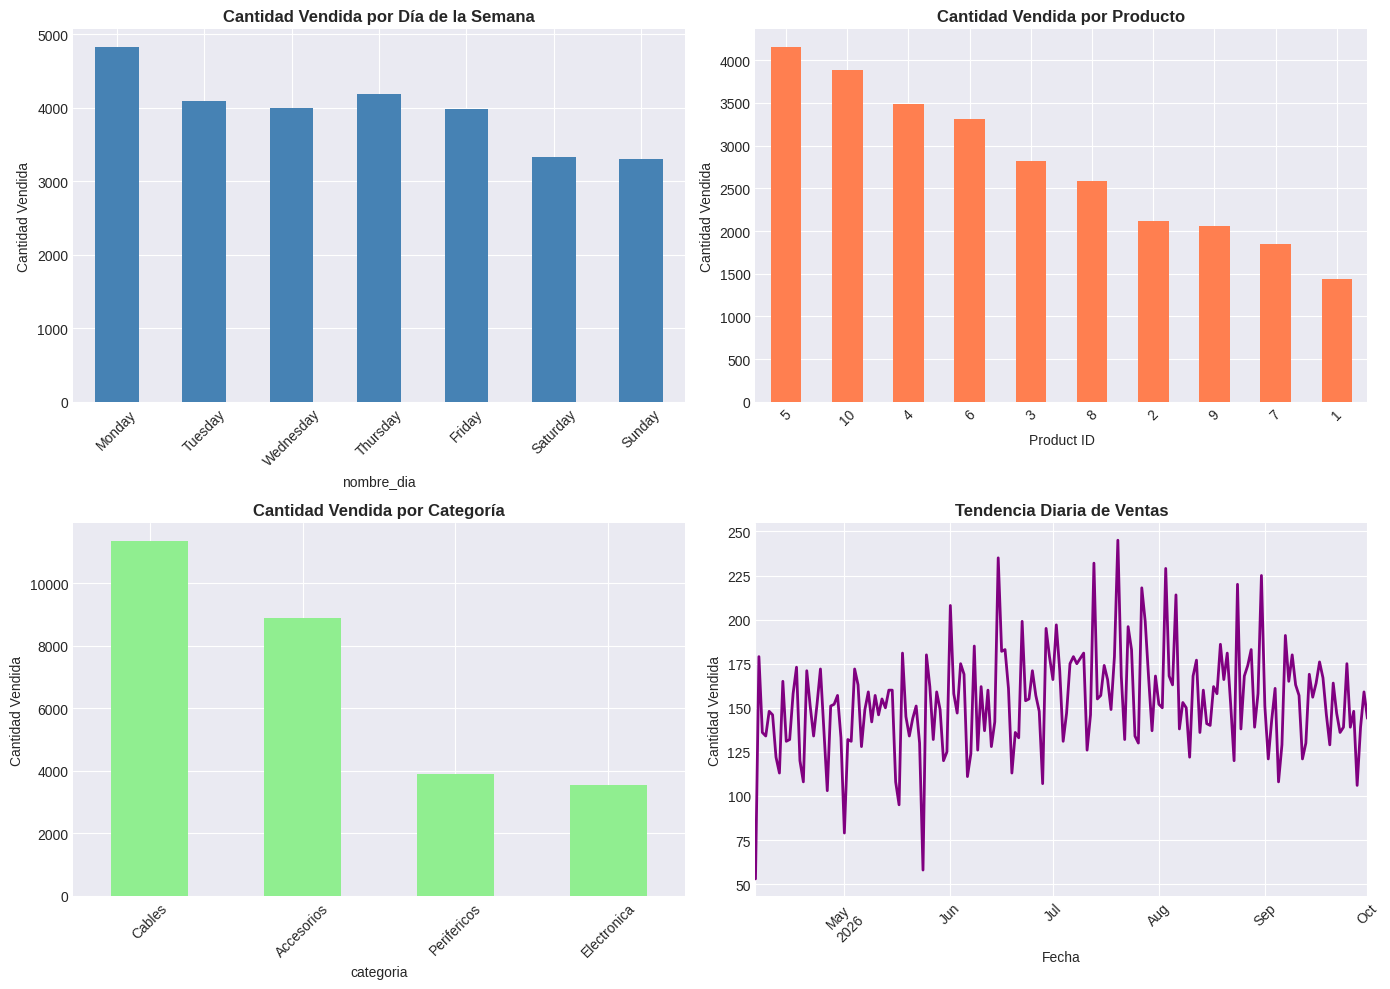

✓ Visualización completada


In [8]:
# Ventas por día de semana
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Ventas por día de semana
daily_sales = df_merged.groupby('nombre_dia')['cantidad_vendida'].sum().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)
daily_sales.plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Cantidad Vendida por Día de la Semana', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Cantidad Vendida')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Ventas por producto
product_sales = df_merged.groupby('product_id')['cantidad_vendida'].sum().sort_values(ascending=False)
product_sales.plot(kind='bar', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Cantidad Vendida por Producto', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Cantidad Vendida')
axes[0, 1].set_xlabel('Product ID')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Ventas por categoría
category_sales = df_merged.groupby('categoria')['cantidad_vendida'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar', ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Cantidad Vendida por Categoría', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Cantidad Vendida')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Evolución temporal de ventas
daily_trend = df_merged.groupby('fecha_venta')['cantidad_vendida'].sum()
daily_trend.plot(ax=axes[1, 1], color='purple', linewidth=2)
axes[1, 1].set_title('Tendencia Diaria de Ventas', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Cantidad Vendida')
axes[1, 1].set_xlabel('Fecha')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("✓ Visualización completada")

### 6. Preparación de Secuencias de Tiempo por Producto

In [9]:
def crear_secuencias(datos, ventana_tiempo=7):
    """
    Crea secuencias temporales para entrenamiento de modelos LSTM.
    
    Params:
        datos: DataFrame con datos temporales ordenados
        ventana_tiempo: número de pasos temporales para predecir el siguiente paso
    
    Returns:
        X, y: Arrays con secuencias de entrada y salida
    """
    X, y = [], []
    
    for i in range(len(datos) - ventana_tiempo):
        X.append(datos[i:i+ventana_tiempo])
        y.append(datos[i+ventana_tiempo])
    
    return np.array(X), np.array(y)

print("Preparando secuencias temporales por producto...")

# Configurar parámetros
VENTANA_TIEMPO = 7  # 7 días para predecir el siguiente día
FEATURES_ENTRADA = ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']

# Diccionario para almacenar datos por producto
secuencias_por_producto = {}
datos_transformados = []

for product_id in df_merged['product_id'].unique():
    df_producto = df_merged[df_merged['product_id'] == product_id].sort_values('fecha_venta').reset_index(drop=True)
    
    # Features para el modelo
    features_disponibles = [f for f in FEATURES_ENTRADA if f in df_producto.columns]
    datos_producto = df_producto[features_disponibles].values
    
    # Crear secuencias
    if len(datos_producto) >= VENTANA_TIEMPO + 1:
        X_seq, y_seq = crear_secuencias(datos_producto, VENTANA_TIEMPO)
        secuencias_por_producto[product_id] = {
            'X': X_seq,
            'y': y_seq,
            'nombre': df_producto['nombre'].iloc[0],
            'categoria': df_producto['categoria'].iloc[0]
        }
        datos_transformados.append({
            'product_id': product_id,
            'num_secuencias': len(X_seq),
            'nombre': df_producto['nombre'].iloc[0],
            'categoria': df_producto['categoria'].iloc[0]
        })

print(f"✓ Secuencias creadas para {len(secuencias_por_producto)} productos")

df_secuencias_info = pd.DataFrame(datos_transformados)
print(f"\nDistribución de secuencias:")
print(df_secuencias_info)
print(f"\nTotal de secuencias: {df_secuencias_info['num_secuencias'].sum()}")

Preparando secuencias temporales por producto...
✓ Secuencias creadas para 10 productos

Distribución de secuencias:
   product_id  num_secuencias            nombre    categoria
0           1             173      Laptop Gamer  Electronica
1           2             173        Monitor 4K  Electronica
2           3             173  Teclado Mecanico   Accesorios
3           4             173       Raton Inal.   Accesorios
4           5             173       Cable USB-C       Cables
5           6             173    Adaptador HDMI       Cables
6           7             173         Webcam HD  Perifericos
7           8             173    Auriculares BT   Accesorios
8           9             173       Hub USB 3.0  Perifericos
9          10             173   Cargador Rapido       Cables

Total de secuencias: 1730


### 7. Separación de Datos (Train, Validation, Test)

In [10]:
print("Separando datos respetando el orden temporal de cada producto...")

# Objetivo: la cantidad vendida del día siguiente (primera variable de la secuencia).
# Cada producto aporta sus primeras semanas a train, las siguientes a validación y las
# últimas a test. Antes se concatenaban los productos y el test quedaba con los últimos
# productos, no con las últimas fechas.
partes = {'train': ([], []), 'val': ([], []), 'test': ([], [])}
for pid, s in secuencias_por_producto.items():
    n = len(s['X'])
    a, b = int(n * 0.6), int(n * 0.8)
    for nombre, (ini, fin) in {'train': (0, a), 'val': (a, b), 'test': (b, n)}.items():
        partes[nombre][0].append(s['X'][ini:fin])
        partes[nombre][1].append(s['y'][ini:fin, :1])

X_train, y_train = (np.concatenate(v) for v in partes['train'])
X_val, y_val = (np.concatenate(v) for v in partes['val'])
X_test, y_test = (np.concatenate(v) for v in partes['test'])
X_todo = np.concatenate([X_train, X_val, X_test])

print(f"\nForma de X: {X_todo.shape}  (secuencias, pasos temporales, features)")
print(f"Número de features de entrada: {X_todo.shape[2]}")
print(f"Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)} secuencias")

Separando datos respetando el orden temporal de cada producto...

Forma de X: (1730, 7, 4)  (secuencias, pasos temporales, features)
Número de features de entrada: 4
Train: 1030  Val: 350  Test: 350 secuencias


## FASE 2: Desarrollo y Entrenamiento de Modelos
### 8. Baseline: Modelo de Regresión Tabulares (Random Forest)

In [11]:
print("="*70)
print("ENTRENAMIENTO MODELO BASELINE: RANDOM FOREST")
print("="*70)

# Para Random Forest, usaremos solo la target (cantidad_vendida)
# Usaremos características tabulares en lugar de secuencias

# Preparar datos tabulares
features_tabla = ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'mes', 
                   'es_fin_semana', 'categoria_encoded', 'proporcion_stock']

df_features = df_merged[features_tabla].copy()
y_target = df_merged['cantidad_vendida'].copy()

# Crear variable objetivo: cantidad_vendida del siguiente día (shift)
df_merged['cantidad_vendida_siguiente'] = df_merged.groupby('product_id')['cantidad_vendida'].shift(-1)

# Remover últimas filas con NaN
mask_valid = df_merged['cantidad_vendida_siguiente'].notna()
X_tabla = df_merged[features_tabla][mask_valid].copy()
y_tabla = df_merged['cantidad_vendida_siguiente'][mask_valid].copy()

print(f"X_tabla shape: {X_tabla.shape}")
print(f"y_tabla shape: {y_tabla.shape}")

# Split train/test
X_train_tabla, X_test_tabla, y_train_tabla, y_test_tabla = train_test_split(
    X_tabla, y_tabla, test_size=0.2, random_state=42, shuffle=False
)

# Entrenar Random Forest
print("\nEntrenando Random Forest...")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1, verbose=1)
rf_model.fit(X_train_tabla, y_train_tabla)

# Predicciones
y_pred_train_rf = rf_model.predict(X_train_tabla)
y_pred_test_rf = rf_model.predict(X_test_tabla)

# Métricas
rmse_train_rf = np.sqrt(mean_squared_error(y_train_tabla, y_pred_train_rf))
rmse_test_rf = np.sqrt(mean_squared_error(y_test_tabla, y_pred_test_rf))
mae_test_rf = mean_absolute_error(y_test_tabla, y_pred_test_rf)
r2_test_rf = r2_score(y_test_tabla, y_pred_test_rf)

print(f"\n✓ Random Forest Entrenado")
print(f"  RMSE Train: {rmse_train_rf:.4f}")
print(f"  RMSE Test: {rmse_test_rf:.4f}")
print(f"  MAE Test: {mae_test_rf:.4f}")
print(f"  R² Test: {r2_test_rf:.4f}")

# Feature importance
feature_importance = pd.DataFrame({
    'feature': features_tabla,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nImportancia de features:")
print(feature_importance)

ENTRENAMIENTO MODELO BASELINE: RANDOM FOREST
X_tabla shape: (1790, 7)
y_tabla shape: (1790,)

Entrenando Random Forest...

✓ Random Forest Entrenado
  RMSE Train: 2.9082
  RMSE Test: 4.6624
  MAE Test: 3.3509
  R² Test: 0.5186

Importancia de features:
             feature  importance
0   cantidad_vendida    0.357281
1   stock_en_momento    0.197241
6   proporcion_stock    0.171562
2         dia_semana    0.120253
5  categoria_encoded    0.111438
3                mes    0.037417
4      es_fin_semana    0.004807


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished


### 9. Modelo Secuencial: LSTM para Series Temporales

In [12]:
print("="*70)
print("ENTRENAMIENTO MODELO LSTM SECUENCIAL")
print("="*70)

# Normalizar datos para la red neuronal
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# Reshape para escalado
n_samples, n_steps, n_features = X_train.shape
X_train_reshaped = X_train.reshape(-1, n_features)
X_train_reshaped = scaler_X.fit_transform(X_train_reshaped)
X_train_scaled = X_train_reshaped.reshape(n_samples, n_steps, n_features)

# Escalar validación y test
X_val_reshaped = X_val.reshape(-1, n_features)
X_val_reshaped = scaler_X.transform(X_val_reshaped)
X_val_scaled = X_val_reshaped.reshape(X_val.shape[0], n_steps, n_features)

X_test_reshaped = X_test.reshape(-1, n_features)
X_test_reshaped = scaler_X.transform(X_test_reshaped)
X_test_scaled = X_test_reshaped.reshape(X_test.shape[0], n_steps, n_features)

# Escalar targets
y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print(f"\n✓ Datos normalizados:")
print(f"  X_train_scaled shape: {X_train_scaled.shape}")
print(f"  y_train_scaled shape: {y_train_scaled.shape}")

ENTRENAMIENTO MODELO LSTM SECUENCIAL

✓ Datos normalizados:
  X_train_scaled shape: (1030, 7, 4)
  y_train_scaled shape: (1030, 1)


In [13]:
print("="*70)
print("ENTRENAMIENTO DE RED NEURONAL RECURRENTE (LSTM) CON KERAS")
print("="*70)

print(f"\n✓ Forma entrada: {X_train_scaled.shape}")

# Construir modelo LSTM con Keras
print("\nConstruyendo modelo LSTM...")
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(n_steps, n_features), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='relu', return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(1)  # cantidad vendida del día siguiente
])

# Compilar
lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

print(f"\n✓ Modelo compilado")
print(f"  Arquitectura:")
print(f"    - Entrada: Secuencias de {n_steps} pasos x {n_features} features")
print(f"    - LSTM Layer 1: 64 unidades + Dropout(0.2) + return_sequences=True")
print(f"    - LSTM Layer 2: 32 unidades + Dropout(0.2)")
print(f"    - Dense Layer: 16 unidades + Dropout(0.1)")
print("    - Salida: Dense(1), la cantidad vendida del día siguiente")

# Definir callbacks
print("\nEntrenando LSTM...")
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=0)

# Entrenar
history = lstm_model.fit(
    X_train_scaled, y_train_scaled,
    epochs=100,
    batch_size=16,
    validation_data=(X_val_scaled, y_val_scaled),
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

print(f"\n✓ LSTM Entrenado")
print(f"  Epocas entrenadas: {len(history.history['loss'])}")
print(f"  Loss final (train): {history.history['loss'][-1]:.6f}")
print(f"  Loss final (val): {history.history['val_loss'][-1]:.6f}")

print(f"\n✓ Preparación completada")

ENTRENAMIENTO DE RED NEURONAL RECURRENTE (LSTM) CON KERAS

✓ Forma entrada: (1030, 7, 4)

Construyendo modelo LSTM...



✓ Modelo compilado
  Arquitectura:
    - Entrada: Secuencias de 7 pasos x 4 features
    - LSTM Layer 1: 64 unidades + Dropout(0.2) + return_sequences=True
    - LSTM Layer 2: 32 unidades + Dropout(0.2)
    - Dense Layer: 16 unidades + Dropout(0.1)
    - Salida: Dense(1), la cantidad vendida del día siguiente

Entrenando LSTM...



✓ LSTM Entrenado
  Epocas entrenadas: 92
  Loss final (train): 0.007837
  Loss final (val): 0.011443

✓ Preparación completada


### 10. Evaluación del Modelo LSTM

In [14]:
print("="*70)
print("EVALUACIÓN DEL MODELO LSTM")
print("="*70)

def predecir(X_escalado):
    return scaler_y.inverse_transform(lstm_model.predict(X_escalado, verbose=0))

y_pred_train_lstm = predecir(X_train_scaled)
y_pred_val_lstm = predecir(X_val_scaled)
y_pred_test_lstm = predecir(X_test_scaled)

rmse_train_lstm = np.sqrt(mean_squared_error(y_train, y_pred_train_lstm))
rmse_val_lstm = np.sqrt(mean_squared_error(y_val, y_pred_val_lstm))
rmse_test_lstm = np.sqrt(mean_squared_error(y_test, y_pred_test_lstm))
mae_test_lstm = mean_absolute_error(y_test, y_pred_test_lstm)
r2_test_lstm = r2_score(y_test, y_pred_test_lstm)

# Referencia ingenua: mañana se vende lo mismo que hoy (último día de la ventana).
y_ingenua = X_test[:, -1, :1]
rmse_ingenua = np.sqrt(mean_squared_error(y_test, y_ingenua))

print(f"RMSE Train: {rmse_train_lstm:.4f}")
print(f"RMSE Val:   {rmse_val_lstm:.4f}")
print(f"RMSE Test:  {rmse_test_lstm:.4f}")
print(f"MAE Test:   {mae_test_lstm:.4f}")
print(f"R² Test:    {r2_test_lstm:.4f}")

print("\n" + "="*70)
print("COMPARACIÓN (cantidad vendida del día siguiente, último 20 % de las fechas)")
print("="*70)
print(f"Referencia ingenua (igual que hoy): RMSE {rmse_ingenua:.4f}")
print(f"Random Forest:                      RMSE {rmse_test_rf:.4f}")
print(f"LSTM:                               RMSE {rmse_test_lstm:.4f}")

EVALUACIÓN DEL MODELO LSTM


RMSE Train: 4.3298
RMSE Val:   5.2144
RMSE Test:  4.7591
MAE Test:   3.5094
R² Test:    0.4952

COMPARACIÓN (cantidad vendida del día siguiente, último 20 % de las fechas)
Referencia ingenua (igual que hoy): RMSE 7.3064
Random Forest:                      RMSE 4.6624
LSTM:                               RMSE 4.7591


### 11. Visualización del Entrenamiento y Predicciones

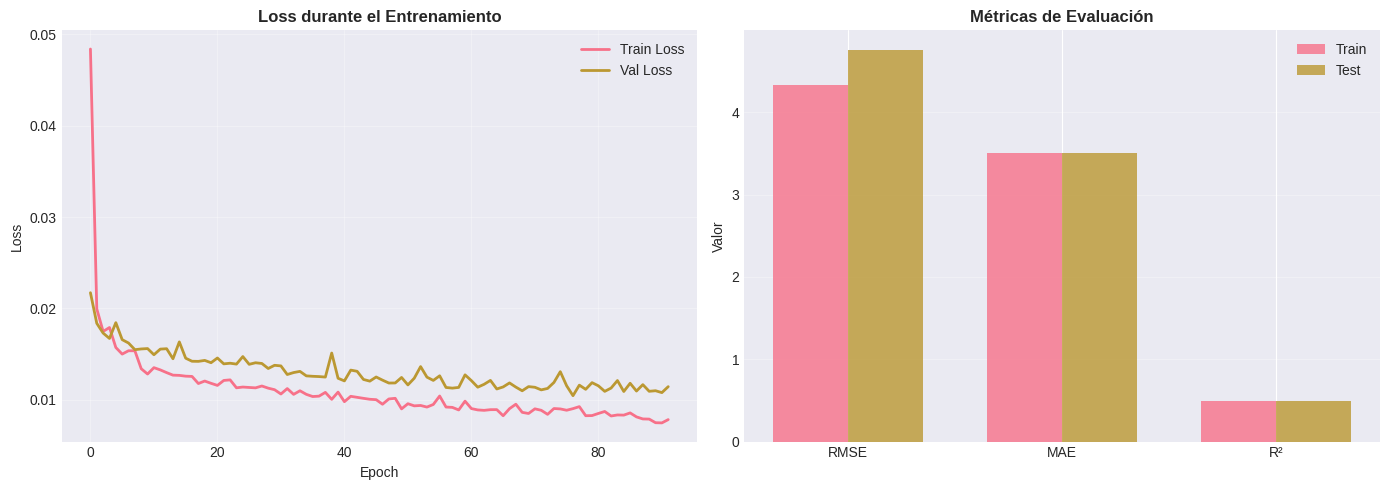

✓ Gráficos de entrenamiento completados


In [15]:
# Gráficos de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Loss durante el Entrenamiento', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Métricas de evaluación
metrics_names = ['RMSE', 'MAE', 'R²']
train_vals = [float(rmse_train_lstm), float(mae_test_lstm), float(r2_test_lstm)]
test_vals = [float(rmse_test_lstm), float(mae_test_lstm), float(r2_test_lstm)]

x_pos = np.arange(len(metrics_names))
width = 0.35

axes[1].bar(x_pos - width/2, train_vals, width, label='Train', alpha=0.8)
axes[1].bar(x_pos + width/2, test_vals, width, label='Test', alpha=0.8)
axes[1].set_title('Métricas de Evaluación', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Valor')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics_names)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("✓ Gráficos de entrenamiento completados")

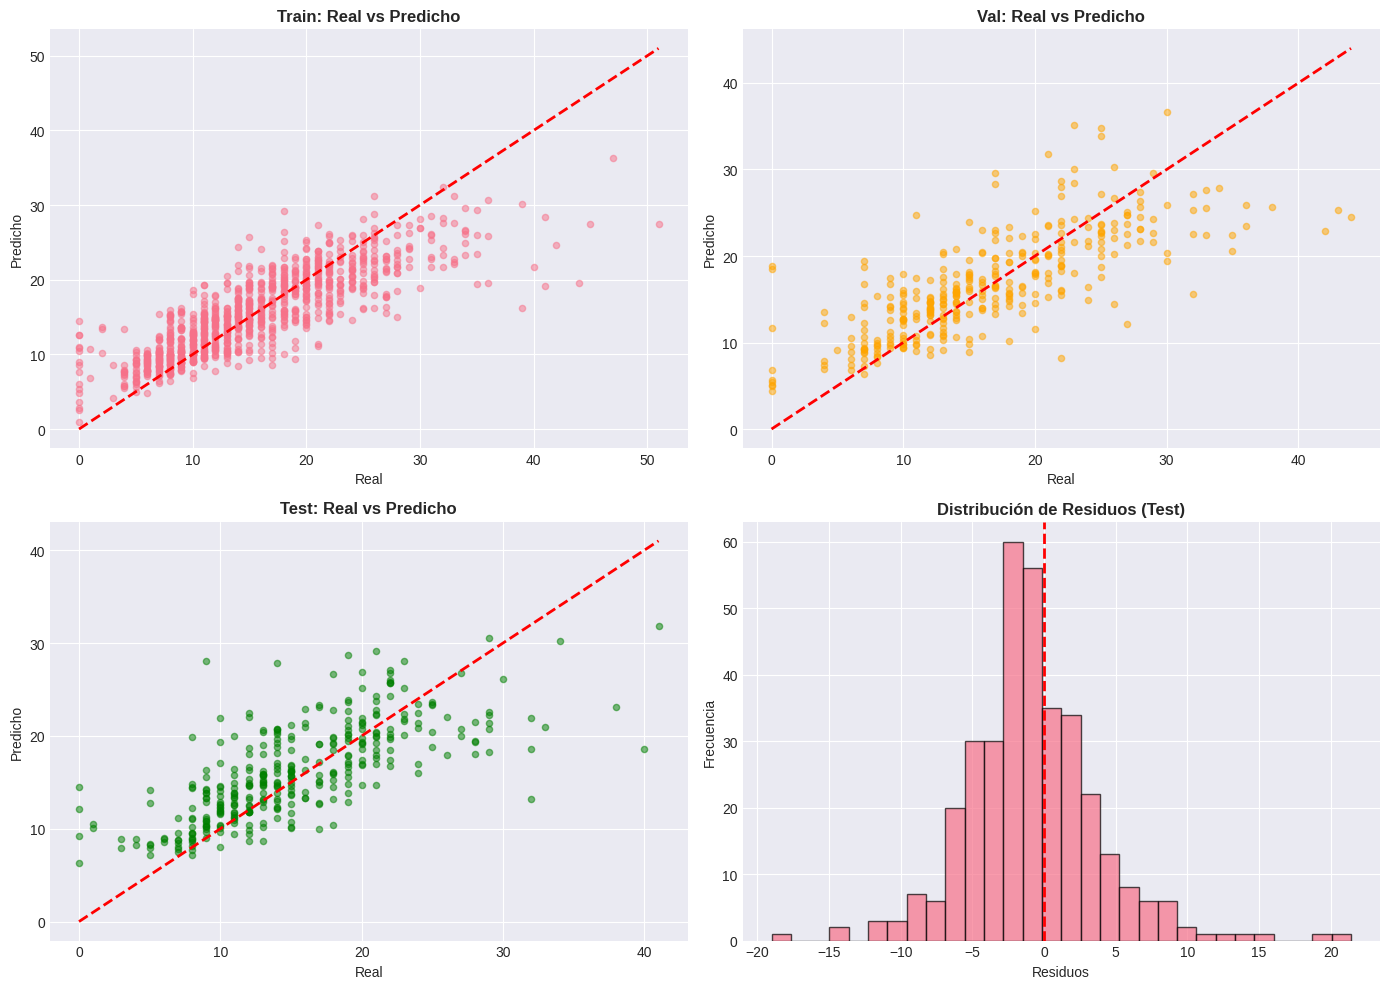

✓ Gráficos de predicciones completados


In [16]:
# Predicciones vs Reales (solo cantidad_vendida que es el primer feature)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Train
axes[0, 0].scatter(y_train[:, 0], y_pred_train_lstm[:, 0], alpha=0.5, s=20)
axes[0, 0].plot([y_train[:, 0].min(), y_train[:, 0].max()], 
                 [y_train[:, 0].min(), y_train[:, 0].max()], 'r--', lw=2)
axes[0, 0].set_title('Train: Real vs Predicho', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicho')

# Val
axes[0, 1].scatter(y_val[:, 0], y_pred_val_lstm[:, 0], alpha=0.5, s=20, color='orange')
axes[0, 1].plot([y_val[:, 0].min(), y_val[:, 0].max()], 
                 [y_val[:, 0].min(), y_val[:, 0].max()], 'r--', lw=2)
axes[0, 1].set_title('Val: Real vs Predicho', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Real')
axes[0, 1].set_ylabel('Predicho')

# Test
axes[1, 0].scatter(y_test[:, 0], y_pred_test_lstm[:, 0], alpha=0.5, s=20, color='green')
axes[1, 0].plot([y_test[:, 0].min(), y_test[:, 0].max()], 
                 [y_test[:, 0].min(), y_test[:, 0].max()], 'r--', lw=2)
axes[1, 0].set_title('Test: Real vs Predicho', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Real')
axes[1, 0].set_ylabel('Predicho')

# Residuos (Test)
residuos = y_test[:, 0] - y_pred_test_lstm[:, 0]
axes[1, 1].hist(residuos, bins=30, edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Distribución de Residuos (Test)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Residuos')
axes[1, 1].set_ylabel('Frecuencia')
axes[1, 1].axvline(x=0, color='r', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()

print("✓ Gráficos de predicciones completados")

## FASE 3: Funciones de Predicción para Despliegue
### 12. Función de Predicción Individual (product_id + fecha)

In [17]:
def predecir_demanda_individual(product_id, fecha_prediccion, modelo, scaler_entrada, scaler_salida, 
                                 df_historico, ventana_tiempo=7, features_entrada=['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']):
    """
    Predice la demanda para un producto específico en una fecha.
    Compatible con Keras LSTM Sequential.
    
    Args:
        product_id (int): ID del producto
        fecha_prediccion (str o datetime): Fecha para la cual predecir
        modelo: Modelo LSTM entrenado
        scaler_entrada: MinMaxScaler para features de entrada
        scaler_salida: MinMaxScaler para targets
        df_historico (DataFrame): Datos históricos del producto
        ventana_tiempo (int): Número de días pasados a usar
        features_entrada (list): Nombres de features
    
    El modelo predice el día siguiente al último registro del producto; si se pide otra
    fecha se avisa en lugar de devolver un número que no corresponde a esa fecha.

    Returns:
        dict: Predicción de la cantidad vendida
    """
    
    # Convertir fecha
    if isinstance(fecha_prediccion, str):
        fecha_prediccion = pd.to_datetime(fecha_prediccion)
    
    # Filtrar datos del producto
    df_prod = df_historico[df_historico['product_id'] == product_id].sort_values('fecha_venta')
    
    if len(df_prod) < ventana_tiempo:
        return {
            'product_id': product_id,
            'fecha': fecha_prediccion,
            'cantidad_vendida_pred': None,
            'error': 'Datos insuficientes para hacer prediccion'
        }
    
    siguiente = df_prod['fecha_venta'].max() + pd.Timedelta(days=1)
    if fecha_prediccion.normalize() != siguiente.normalize():
        return {
            'product_id': product_id,
            'fecha': fecha_prediccion.strftime('%Y-%m-%d'),
            'cantidad_vendida_pred': None,
            'error': f"El modelo predice el día siguiente al último registro ({siguiente.date()})"
        }

    # Obtener últimas ventana_tiempo observaciones
    df_ventana = df_prod[features_entrada].tail(ventana_tiempo).values
    
    # Normalizar
    n_features_actual = df_ventana.shape[1]
    df_ventana_scaled = scaler_entrada.transform(df_ventana.reshape(-1, n_features_actual))
    
    # Reshape para LSTM: (1, ventana_tiempo, n_features)
    df_ventana_lstm = df_ventana_scaled.reshape(1, ventana_tiempo, n_features_actual)
    
    # Predicción LSTM
    pred_scaled = modelo.predict(df_ventana_lstm, verbose=0)
    pred = scaler_salida.inverse_transform(pred_scaled)
    
    cantidad_pred = max(0, float(pred[0, 0]))
    
    # Obtener nombre
    nombre = df_prod['nombre'].iloc[-1]
    
    return {
        'product_id': product_id,
        'nombre': nombre,
        'fecha': fecha_prediccion.strftime('%Y-%m-%d'),
        'cantidad_vendida_predicha': round(cantidad_pred, 2),
        'error_tipico_test': round(float(mae_test_lstm), 2)
    }

print("✓ Funcion predecir_demanda_individual() definida")

✓ Funcion predecir_demanda_individual() definida


### 13. Función de Predicción Batch (múltiples productos, misma fecha)

In [18]:
def predecir_demanda_batch(product_ids, fecha_prediccion, modelo, scaler_entrada, scaler_salida,
                           df_historico, ventana_tiempo=7, features_entrada=['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock']):
    """
    Predice la demanda para múltiples productos en la misma fecha.
    
    Args:
        product_ids (list): Lista de IDs de productos
        fecha_prediccion (str o datetime): Fecha para la cual predecir
        modelo: Modelo LSTM entrenado
        scaler_entrada: MinMaxScaler para features
        scaler_salida: MinMaxScaler para targets
        df_historico (DataFrame): Datos históricos
        ventana_tiempo (int): Número de días pasados
        features_entrada (list): Nombres de features
    
    Returns:
        DataFrame: Predicciones para todos los productos
    """
    
    predicciones = []
    
    for product_id in product_ids:
        pred = predecir_demanda_individual(
            product_id, fecha_prediccion, modelo, scaler_entrada, scaler_salida,
            df_historico, ventana_tiempo, features_entrada
        )
        predicciones.append(pred)
    
    return pd.DataFrame(predicciones)

print("✓ Función predecir_demanda_batch() definida")

✓ Función predecir_demanda_batch() definida


### 14. Ejemplos de Uso de Funciones de Predicción

In [19]:
print("="*70)
print("EJEMPLOS DE PREDICCIÓN")
print("="*70)

# Predicción Individual
print("\n1. PREDICCIÓN INDIVIDUAL (product_id=3, fecha=2026-10-02)")
print("-" * 70)

pred_individual = predecir_demanda_individual(
    product_id=3,
    fecha_prediccion='2026-10-02',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nResultado:")
for key, value in pred_individual.items():
    print(f"  {key:25s}: {value}")

EJEMPLOS DE PREDICCIÓN

1. PREDICCIÓN INDIVIDUAL (product_id=3, fecha=2026-10-02)
----------------------------------------------------------------------

Resultado:
  product_id               : 3
  nombre                   : Teclado Mecanico
  fecha                    : 2026-10-02
  cantidad_vendida_predicha: 17.09
  error_tipico_test        : 3.51


In [20]:
# Predicción Batch
print("\n2. PREDICCIÓN BATCH (múltiples productos, fecha=2026-10-02)")
print("-" * 70)

products_batch = [1, 3, 5, 7, 9]
pred_batch = predecir_demanda_batch(
    product_ids=products_batch,
    fecha_prediccion='2026-10-02',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nResultados:")
print(pred_batch.to_string(index=False))


2. PREDICCIÓN BATCH (múltiples productos, fecha=2026-10-02)
----------------------------------------------------------------------



Resultados:
 product_id           nombre      fecha  cantidad_vendida_predicha  error_tipico_test
          1     Laptop Gamer 2026-10-02                       9.38               3.51
          3 Teclado Mecanico 2026-10-02                      17.09               3.51
          5      Cable USB-C 2026-10-02                      19.74               3.51
          7        Webcam HD 2026-10-02                      10.81               3.51
          9      Hub USB 3.0 2026-10-02                       9.93               3.51


In [21]:
# Predicción para todos los productos
print("\n3. PREDICCIÓN PARA TODOS LOS PRODUCTOS")
print("-" * 70)

todos_ids = df_merged['product_id'].unique().tolist()
pred_todos = predecir_demanda_batch(
    product_ids=todos_ids,
    fecha_prediccion='2026-10-02',
    modelo=lstm_model,
    scaler_entrada=scaler_X,
    scaler_salida=scaler_y,
    df_historico=df_merged,
    ventana_tiempo=7
)

print(f"\nPredicciones para {len(pred_todos)} productos:")
print(pred_todos.to_string(index=False))


3. PREDICCIÓN PARA TODOS LOS PRODUCTOS
----------------------------------------------------------------------



Predicciones para 10 productos:
 product_id           nombre      fecha  cantidad_vendida_predicha  error_tipico_test
          1     Laptop Gamer 2026-10-02                       9.38               3.51
          2       Monitor 4K 2026-10-02                      12.38               3.51
          3 Teclado Mecanico 2026-10-02                      17.09               3.51
          4      Raton Inal. 2026-10-02                      17.84               3.51
          5      Cable USB-C 2026-10-02                      19.74               3.51
          6   Adaptador HDMI 2026-10-02                      18.07               3.51
          7        Webcam HD 2026-10-02                      10.81               3.51
          8   Auriculares BT 2026-10-02                      14.91               3.51
          9      Hub USB 3.0 2026-10-02                       9.93               3.51
         10  Cargador Rapido 2026-10-02                      19.67               3.51


### 15. Guardado del Modelo y Artefactos para Despliegue

In [22]:
import os
import json

print("="*70)
print("GUARDANDO MODELO Y ARTEFACTOS")
print("="*70)

# Crear carpeta de modelos
models_dir = os.path.join(base_path, 'modelos')
os.makedirs(models_dir, exist_ok=True)

# Guardar el modelo de Keras en su formato (pickle no sirve para modelos de Keras)
model_path = os.path.join(models_dir, 'lstm_demanda.keras')
lstm_model.save(model_path)
print(f"✓ Modelo LSTM guardado: {model_path}")

# Guardar escaladores
scaler_X_path = os.path.join(models_dir, 'scaler_X.pkl')
scaler_y_path = os.path.join(models_dir, 'scaler_y.pkl')

with open(scaler_X_path, 'wb') as f:
    pickle.dump(scaler_X, f)
print(f"✓ Scaler X guardado: {scaler_X_path}")

with open(scaler_y_path, 'wb') as f:
    pickle.dump(scaler_y, f)
print(f"✓ Scaler y guardado: {scaler_y_path}")

# Guardar configuración
config = {
    'ventana_tiempo': 7,
    'features_entrada': ['cantidad_vendida', 'stock_en_momento', 'dia_semana', 'proporcion_stock'],
    'n_features': n_features,
    'n_steps': n_steps,
    'rmse_test': float(rmse_test_lstm),
    'mae_test': float(mae_test_lstm),
    'r2_test': float(r2_test_lstm),
    'fecha_entrenamiento': datetime.now().isoformat(),
    'modelos': {
        'red_neuronal': {
            'tipo': 'LSTM (Keras)',
            'arquitectura': '7 pasos x 4 features -> LSTM(64) -> LSTM(32) -> Dense(16) -> Dense(1)',
            'rmse': float(rmse_test_lstm),
            'mae': float(mae_test_lstm),
            'r2': float(r2_test_lstm)
        },
        'random_forest_baseline': {
            'rmse': float(rmse_test_rf),
            'mae': float(mae_test_rf),
            'r2': float(r2_test_rf)
        }
    }
}

config_path = os.path.join(models_dir, 'config.json')
with open(config_path, 'w') as f:
    json.dump(config, f, indent=2)
print(f"✓ Configuración guardada: {config_path}")

# Resumen
print(f"\n" + "="*70)
print("ARTEFACTOS GUARDADOS")
print("="*70)
print(f"\nCarpeta: {models_dir}")
for archivo in os.listdir(models_dir):
    ruta = os.path.join(models_dir, archivo)
    if os.path.isfile(ruta):
        tamaño = os.path.getsize(ruta) / 1024
        print(f"  - {archivo:30s} ({tamaño:.2f} KB)")

GUARDANDO MODELO Y ARTEFACTOS
✓ Modelo LSTM guardado: ./modelos/lstm_demanda.keras
✓ Scaler X guardado: ./modelos/scaler_X.pkl
✓ Scaler y guardado: ./modelos/scaler_y.pkl
✓ Configuración guardada: ./modelos/config.json

ARTEFACTOS GUARDADOS

Carpeta: ./modelos
  - lstm_demanda.keras             (402.00 KB)
  - scaler_X.pkl                   (0.63 KB)
  - scaler_y.pkl                   (0.51 KB)
  - config.json                    (0.72 KB)


### 16. Reporte Final

In [23]:
print("\n" + "="*70)
print("REPORTE FINAL - PREDICCION DE DEMANDA EN RETAIL")
print("="*70)

print(f"\n[DATASET GENERADO]")
print("-" * 70)
print(f"  - Productos: {len(todos_ids)}")
print(f"  - Transacciones: {len(sales_df)}")
print(f"  - Periodo: {sales_df['fecha_venta'].min().date()} a {sales_df['fecha_venta'].max().date()}")
print(f"  - Categorias: {df_merged['categoria'].nunique()}")

print(f"\n[FEATURE ENGINEERING]")
print("-" * 70)
print(f"  - Features temporales: dia_semana, mes, es_fin_semana, semana_ano")
print(f"  - Features derivadas: dias_desde_inicio, dias_para_expiracion")
print(f"  - Features de proporcion: stock_actual, proporcion_stock")
print(f"  - Encoding categorico: categoria_encoded")
print(f"  - Total de features: {n_features}")

print(f"\n[SECUENCIAS TEMPORALES]")
print("-" * 70)
print(f"  - Ventana de tiempo: {n_steps} dias")
print(f"  - Total de secuencias: {len(X_todo)}")
print(f"  - Train: {len(X_train)} secuencias (60%)")
print(f"  - Val: {len(X_val)} secuencias (20%)")
print(f"  - Test: {len(X_test)} secuencias (20%)")

print(f"\n[MODELOS ENTRENADOS]")
print("-" * 70)
print(f"\n  Baseline (Random Forest):")
print(f"    RMSE Test: {rmse_test_rf:.4f}")
print(f"    MAE Test:  {mae_test_rf:.4f}")
print(f"    R2 Test:   {r2_test_rf:.4f}")
print(f"\n  Modelo LSTM (RNN Secuencial):") 
print(f"    RMSE Train: {rmse_train_lstm:.4f}")
print(f"    RMSE Val:   {rmse_val_lstm:.4f}")
print(f"    RMSE Test:  {rmse_test_lstm:.4f}")
print(f"    MAE Test:   {mae_test_lstm:.4f}")
print(f"    R2 Test:    {r2_test_lstm:.4f}")
print(f"\n  Mejora LSTM vs Baseline: {((rmse_test_rf - rmse_test_lstm) / rmse_test_rf * 100):.2f}%")

print(f"\n[ARQUITECTURA LSTM]")
print("-" * 70)
print(f"  - Entrada: {n_steps} pasos temporales × {n_features} features")
print(f"  - LSTM Layer 1: 64 unidades + Dropout(0.2) + return_sequences=True")
print(f"  - LSTM Layer 2: 32 unidades + Dropout(0.2)")
print(f"  - Dense Layer: 16 unidades + Dropout(0.1)")
print(f"  - Salida: Dense({n_features})")
print(f"  - Optimizador: Adam (lr=0.001)")
print(f"  - Callbacks: EarlyStopping, ReduceLROnPlateau")

print(f"\n[ARTEFACTOS GUARDADOS]")
print("-" * 70)
print(f"  - Modelo LSTM: {model_path}")
print(f"  - Scalers: {scaler_X_path}, {scaler_y_path}")
print(f"  - Configuracion: {config_path}")

print(f"\n[FUNCIONES DE PREDICCION DISPONIBLES]")
print("-" * 70)
print(f"  1. predecir_demanda_individual(product_id, fecha)")
print(f"     - Predice demanda para 1 producto en una fecha")
print(f"  2. predecir_demanda_batch(product_ids, fecha)")
print(f"     - Predice demanda para multiples productos en la misma fecha")

print(f"\n" + "="*70)
print(f"Proyecto completado exitosamente")
print("="*70)


REPORTE FINAL - PREDICCION DE DEMANDA EN RETAIL

[DATASET GENERADO]
----------------------------------------------------------------------
  - Productos: 10
  - Transacciones: 1800
  - Periodo: 2026-04-05 a 2026-10-01
  - Categorias: 4

[FEATURE ENGINEERING]
----------------------------------------------------------------------
  - Features temporales: dia_semana, mes, es_fin_semana, semana_ano
  - Features derivadas: dias_desde_inicio, dias_para_expiracion
  - Features de proporcion: stock_actual, proporcion_stock
  - Encoding categorico: categoria_encoded
  - Total de features: 4

[SECUENCIAS TEMPORALES]
----------------------------------------------------------------------
  - Ventana de tiempo: 7 dias
  - Total de secuencias: 1730
  - Train: 1030 secuencias (60%)
  - Val: 350 secuencias (20%)
  - Test: 350 secuencias (20%)

[MODELOS ENTRENADOS]
----------------------------------------------------------------------

  Baseline (Random Forest):
    RMSE Test: 4.6624
    MAE Test:  3